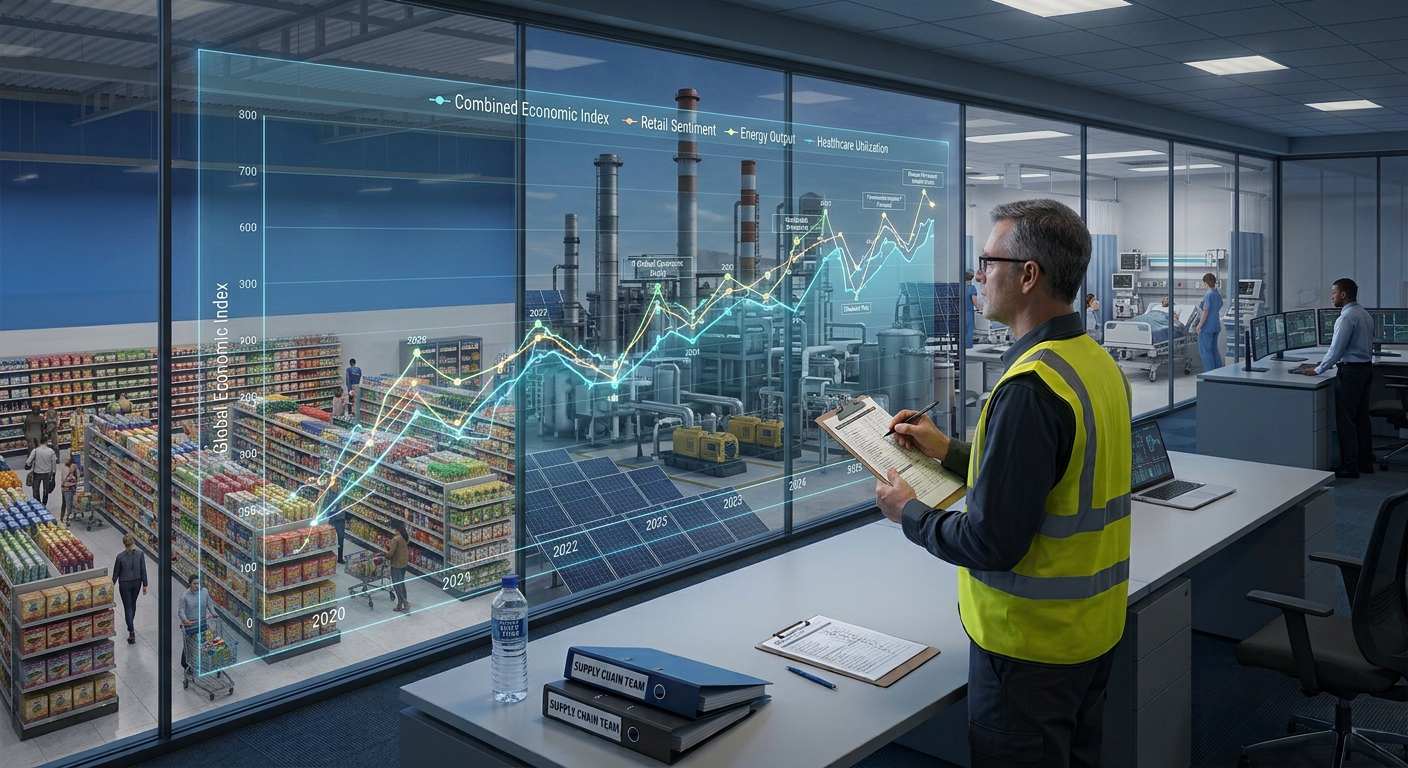

# Multi Sector Time Series Demand and Capacity Planning

## Business Importance
Time series forecasting plays an important role in understanding historical patterns, identifying trends, and anticipating future changes in sequential data. By analyzing observations over time, organizations can improve their ability to predict future outcomes, recognize recurring seasonal patterns, and make more informed decisions under uncertainty.

The application of time series models provides a structured approach to understanding temporal dependencies and extracting meaningful information from historical data. Depending on the nature of the dataset, incorporating external variables can further improve forecasting performance and provide additional insights into the factors influencing the observed patterns.

## Business Problem
Historical data often contains trends, seasonal fluctuations, irregular variations, and temporal dependencies that make future values difficult to predict using conventional analytical approaches.

The main challenge is identifying an appropriate time series methodology capable of capturing these characteristics while producing reliable forecasts. Additionally, different datasets may exhibit distinct temporal structures, requiring careful model selection, data preparation, and performance evaluation.

Without an appropriate forecasting approach, organizations may struggle to anticipate future developments and identify meaningful patterns within their historical data.

## Project Objective
Develop and evaluate time series forecasting models to analyze historical observations, identify temporal patterns, and predict future values.

The project aims to explore and apply different forecasting methodologies according to the characteristics of each dataset, assessing their ability to capture trends, seasonality, and temporal dependencies.

Model performance will be evaluated using appropriate statistical metrics and visual analysis to identify the most suitable forecasting approach for each scenario. The ultimate objective is to develop a practical understanding of time series techniques and their application to real-world datasets across different industries.

## Sectors involved

1. Retail
2. Energy
3. Healthcare

## RETAIL SECTOR

### Importing all libraries necessary for our analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_absolute_error, mean_squared_error

### Defining the dataset

In [13]:
df = pd.read_csv("Retail_Sales_Economics.csv", sep= ";")
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

### Getting columns information

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Store         6435 non-null   int64         
 1   Date          6435 non-null   datetime64[ns]
 2   Weekly_Sales  6435 non-null   float64       
 3   CPI           6435 non-null   float64       
 4   Unemployment  6435 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(1)
memory usage: 251.5 KB


### Printing the dataset

In [15]:
df

,Store,Date,Weekly_Sales,CPI,Unemployment
0,1,2010-02-05,1643690.90,211.096358,8.106
1,1,2010-02-12,1641957.44,211.242170,8.106
2,1,2010-02-19,1611968.17,211.289143,8.106
3,1,2010-02-26,1409727.59,211.319643,8.106
4,1,2010-03-05,1554806.68,211.350143,8.106
...,...,...,...,...,...
6430,45,2012-09-28,713173.95,192.013558,8.684
6431,45,2012-10-05,733455.07,192.170412,8.667
6432,45,2012-10-12,734464.36,192.327265,8.667
6433,45,2012-10-19,718125.53,192.330854,8.667


### Exploratory Data Analysis

#### Variables fluctuation

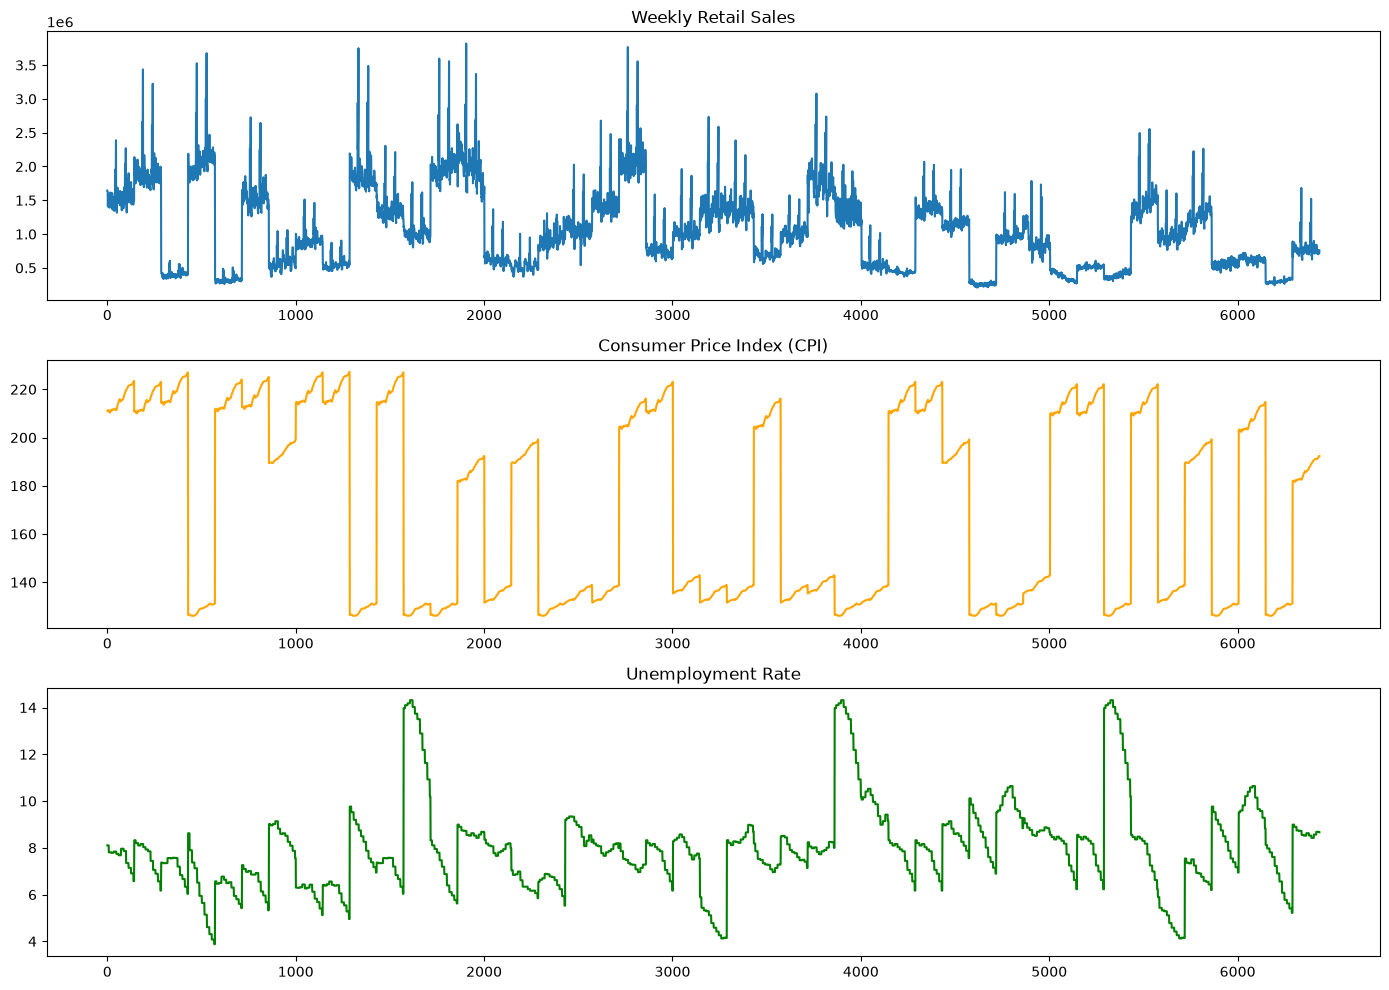

In [17]:
fig, ax = plt.subplots(3, 1, figsize=(14, 10))

df["Weekly_Sales"].plot(ax=ax[0], title="Weekly Retail Sales")
df["CPI"].plot(ax=ax[1], title="Consumer Price Index (CPI)", color="orange")
df["Unemployment"].plot(ax=ax[2], title="Unemployment Rate", color="green")

plt.tight_layout()
plt.show()

**Conclusion:** The initial visualization provides an overview of the temporal behavior of each variable. Weekly sales exhibit fluctuations that may reflect underlying trends and seasonal patterns, while CPI and unemployment provide additional economic context. These observations support the need for a forecasting approach capable of capturing temporal dependencies and potentially incorporating external explanatory variables.

#### Seasonal Decomposition

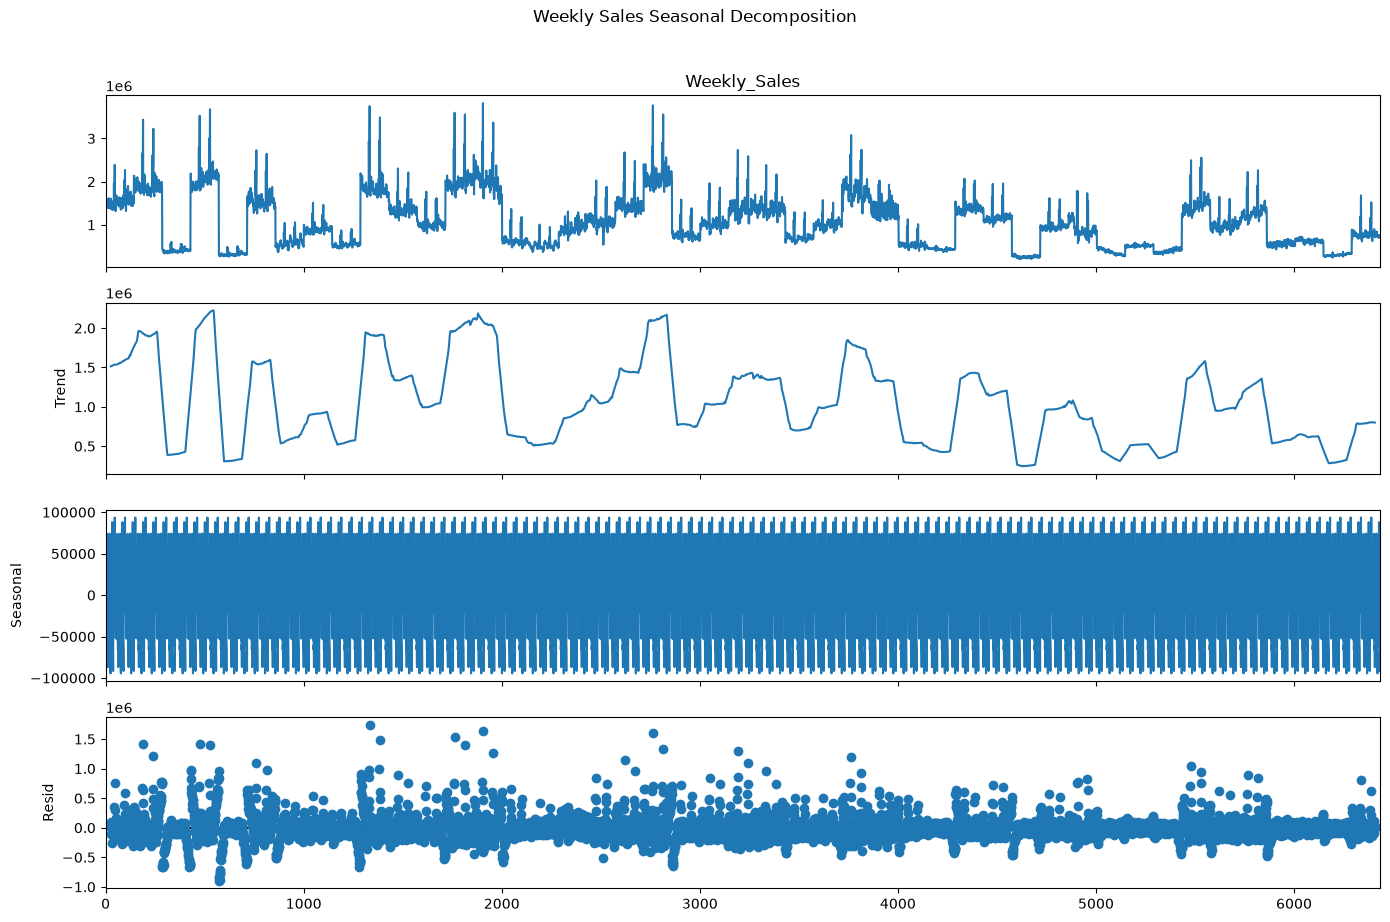

In [19]:
decomposition = seasonal_decompose(
    df["Weekly_Sales"],
    model="additive",
    period=52
)

fig = decomposition.plot()
fig.set_size_inches(14, 9)
fig.suptitle("Weekly Sales Seasonal Decomposition", y=1.02)

plt.tight_layout()
plt.show()

**Conclusion:** The decomposition helps determine whether weekly sales contain a consistent long-term trend and recurring annual seasonal patterns. The residual component represents variations that are not explained by these two components. Identifying these characteristics is important when selecting a forecasting model, particularly when considering seasonal ARIMA methodologies.

#### Correlation Analysis

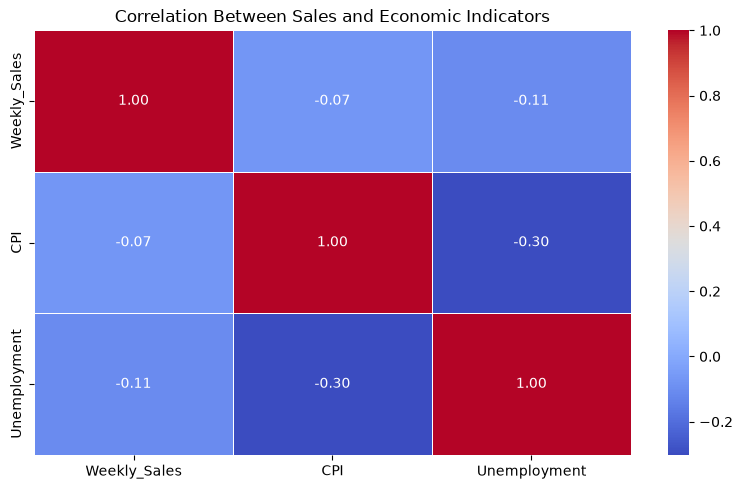

In [21]:
correlation = df[["Weekly_Sales", "CPI", "Unemployment"]].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Sales and Economic Indicators")
plt.tight_layout()
plt.show()

**Conclusion:** The correlation matrix provides an initial assessment of the linear relationships between weekly sales, CPI, and unemployment. Strong correlations may indicate potential associations, although they do not establish causality or guarantee predictive value. The results will help guide the selection of explanatory variables for the SARIMAX model.

### Creating the SARIMAX

#### Creating the training and testing datasets

In [24]:
target = df["Weekly_Sales"]
exog = df[["CPI", "Unemployment"]]

split = int(len(df) * 0.80)

y_train, y_test = target.iloc[:split], target.iloc[split:]
X_train, X_test = exog.iloc[:split], exog.iloc[split:]

print("Training observations:", len(y_train))
print("Testing observations:", len(y_test))
print("Training period:", y_train.index.min(), "to", y_train.index.max())
print("Testing period:", y_test.index.min(), "to", y_test.index.max())

Training observations: 5148
Testing observations: 1287
Training period: 0 to 5147
Testing period: 5148 to 6434


#### Training the model and its stats

In [25]:
model = SARIMAX(
    y_train,
    exog=X_train,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 52),
    enforce_stationarity=False,
    enforce_invertibility=False
)

results = model.fit(disp=False)

print(results.summary())

                                     SARIMAX Results                                      
Dep. Variable:                       Weekly_Sales   No. Observations:                 5148
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 52)   Log Likelihood              -68460.050
Date:                            Mon, 16 Nov 2026   AIC                         136934.100
Time:                                    12:43:28   BIC                         136979.850
Sample:                                         0   HQIC                        136950.120
                                           - 5148                                         
Covariance Type:                              opg                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
CPI          -4577.8924    125.329    -36.527      0.000   -4823.533   -4332.252
Unemployment -2.529e+04   295

**Conclusion:** This statistical model analyzes over 5,000 weeks of data to confirm that both rising inflation and increasing unemployment have a significant negative impact on weekly sales, while also accounting for annual seasonal shopping patterns. However, the data is highly volatile with frequent extreme spikes, meaning historical patterns occasionally break from the norm. Finally, a technical warning suggests that inflation and unemployment might be moving too closely together, meaning you should trust the general finding that these factors drive sales down, but remain cautious about the precise numerical predictions.

#### Sales forecasting

In [26]:
forecast = results.get_forecast(
    steps=len(y_test),
    exog=X_test
)

predictions = forecast.predicted_mean
confidence = forecast.conf_int()

#### Model Evaluation metrics

In [27]:
mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(mean_squared_error(y_test, predictions))

mape = np.mean(
    np.abs((y_test - predictions) / y_test)
) * 100

print(f"Mean Absolute Error (MAE): ${mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")

Mean Absolute Error (MAE): $449,346.70
Root Mean Squared Error (RMSE): $580,231.92
Mean Absolute Percentage Error (MAPE): 57.70%


**Conclusion:** The model's prediction errors are quite large in absolute terms, with an average miss of about USD 449,000 per week and larger errors of roughly USD 580,000 when heavy penalties are applied to big misses. More concerning is the MAPE of 57.70%, which means the forecasts are off by more than half of the actual sales value on average, a strong signal that the model's predictive accuracy is poor. While the model correctly identifies that inflation and unemployment push sales down, these error metrics reveal it is not reliable for precise weekly forecasting. This poor accuracy likely stems from the extreme volatility and outliers flagged earlier, meaning the model captures the general direction of sales but cannot be trusted to predict exact dollar figures.

#### Plotting Actual vs. Predicted Sales

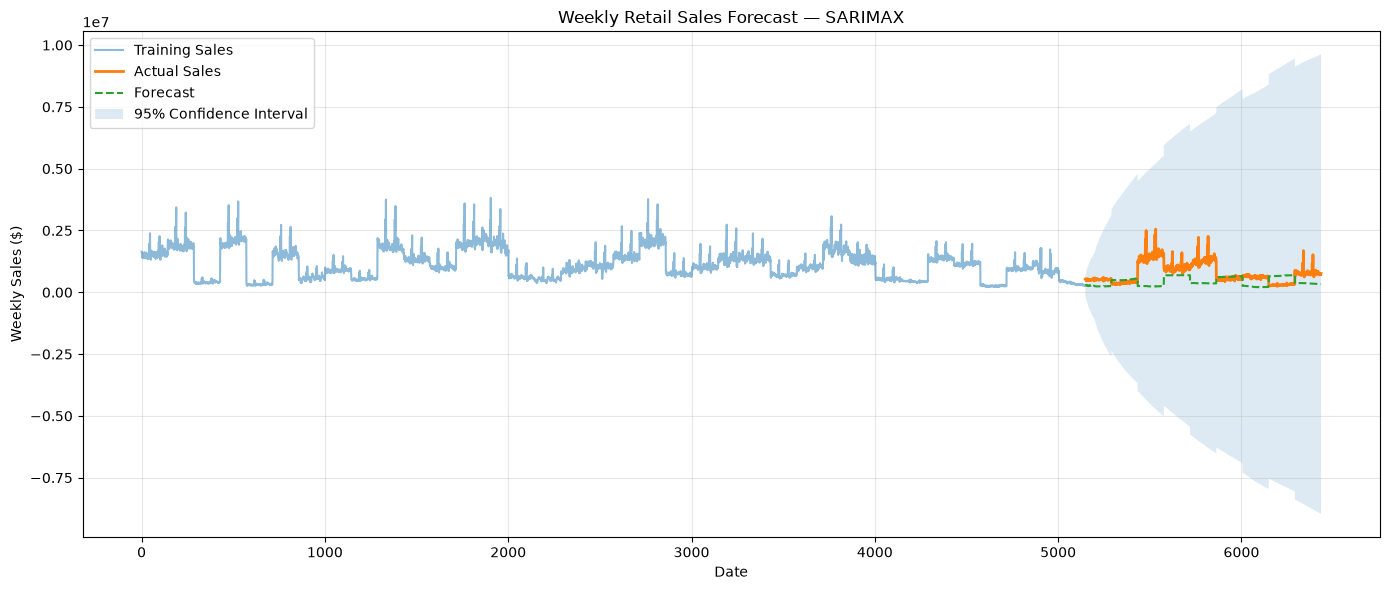

In [28]:
plt.figure(figsize=(14, 6))

plt.plot(y_train.index, y_train, label="Training Sales", alpha=0.5)
plt.plot(y_test.index, y_test, label="Actual Sales", linewidth=2)
plt.plot(predictions.index, predictions, label="Forecast", linestyle="--")

plt.fill_between(
    confidence.index,
    confidence.iloc[:, 0],
    confidence.iloc[:, 1],
    alpha=0.15,
    label="95% Confidence Interval"
)

plt.title("Weekly Retail Sales Forecast — SARIMAX")
plt.xlabel("Date")
plt.ylabel("Weekly Sales ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Conclusion:** This chart visually confirms that the forecasting model is unreliable, as the predicted sales (dashed green line) completely fail to capture the actual highly volatile sales fluctuations (orange line) during the test period. The huge, expanding light blue shaded area, representing the 95% confidence interval, indicates massive uncertainty, showing the model is essentially guessing that future sales could be anywhere from way below zero to far above the historical peaks.

#### Weekly Sales Prediction

In [31]:
# Interactive SARIMAX Forecast Calculator

forecast_date = "2026-01-06"
cpi = 225.5
unemployment = 7.8

# Prepare future explanatory variables
future_exog = pd.DataFrame(
    {
        "CPI": [cpi],
        "Unemployment": [unemployment]
    },
    index=pd.DatetimeIndex([pd.to_datetime(forecast_date)])
)

# Generate forecast
future_forecast = results.get_forecast(
    steps=1,
    exog=future_exog
)

predicted_sales = future_forecast.predicted_mean.iloc[0]
confidence_interval = future_forecast.conf_int()

lower_bound = confidence_interval.iloc[0, 0]
upper_bound = confidence_interval.iloc[0, 1]

# Display results
print(f"Forecast Date: {forecast_date}")
print(f"Predicted Weekly Sales: ${predicted_sales:,.2f}")
print(f"Lower Confidence Bound: ${lower_bound:,.2f}")
print(f"Upper Confidence Bound: ${upper_bound:,.2f}")
print(f"Confidence Level: 95%")

print("\nHistorical Model Performance")
print(f"MAE: ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"MAPE: {mape:.2f}%")

Forecast Date: 2026-01-06
Predicted Weekly Sales: $225,160.14
Lower Confidence Bound: $-129,234.32
Upper Confidence Bound: $579,554.59
Confidence Level: 95%

Historical Model Performance
MAE: $449,346.70
RMSE: $580,231.92
MAPE: 57.70%


**Conclusion:** For the time series forecast dated January 6, 2026, the model predicts a weekly sales value of USD 225,160.14. To account for temporal uncertainty, this time series projection includes a 95% confidence interval ranging from a lower bound of USD -129,234.32 to an upper bound of USD 579,554.59. However, the historical performance of this time series model indicates significant deviation from actual past observations, evidenced by a mean absolute error of USD 449,346.70, a root mean square error of USD 580,231.92, and a mean absolute percentage error of 57.70%.

## ENERGY SECTOR

### Importing libraries, dataset and set up

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy.stats import genpareto, spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

df = pd.read_csv("powerconsumption.csv", sep = ";")
df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")
df

,Datetime,Temperature,Humidity,PowerConsumption
0,2017-01-01 00:00:00,6.559,73.8,34055.69620
1,2017-01-01 00:10:00,6.414,74.5,29814.68354
2,2017-01-01 00:20:00,6.313,74.5,29128.10127
3,2017-01-01 00:30:00,6.121,75.0,28228.86076
4,2017-01-01 00:40:00,5.921,75.7,27335.69620
...,...,...,...,...
52411,2017-12-30 23:10:00,7.010,72.4,31160.45627
52412,2017-12-30 23:20:00,6.947,72.6,30430.41825
52413,2017-12-30 23:30:00,6.900,72.8,29590.87452
52414,2017-12-30 23:40:00,6.758,73.0,28958.17490


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Datetime          52416 non-null  datetime64[ns]
 1   Temperature       52416 non-null  float64       
 2   Humidity          52416 non-null  float64       
 3   PowerConsumption  52416 non-null  float64       
dtypes: datetime64[ns](1), float64(3)
memory usage: 1.6 MB


#### Electricity Demand Behavior

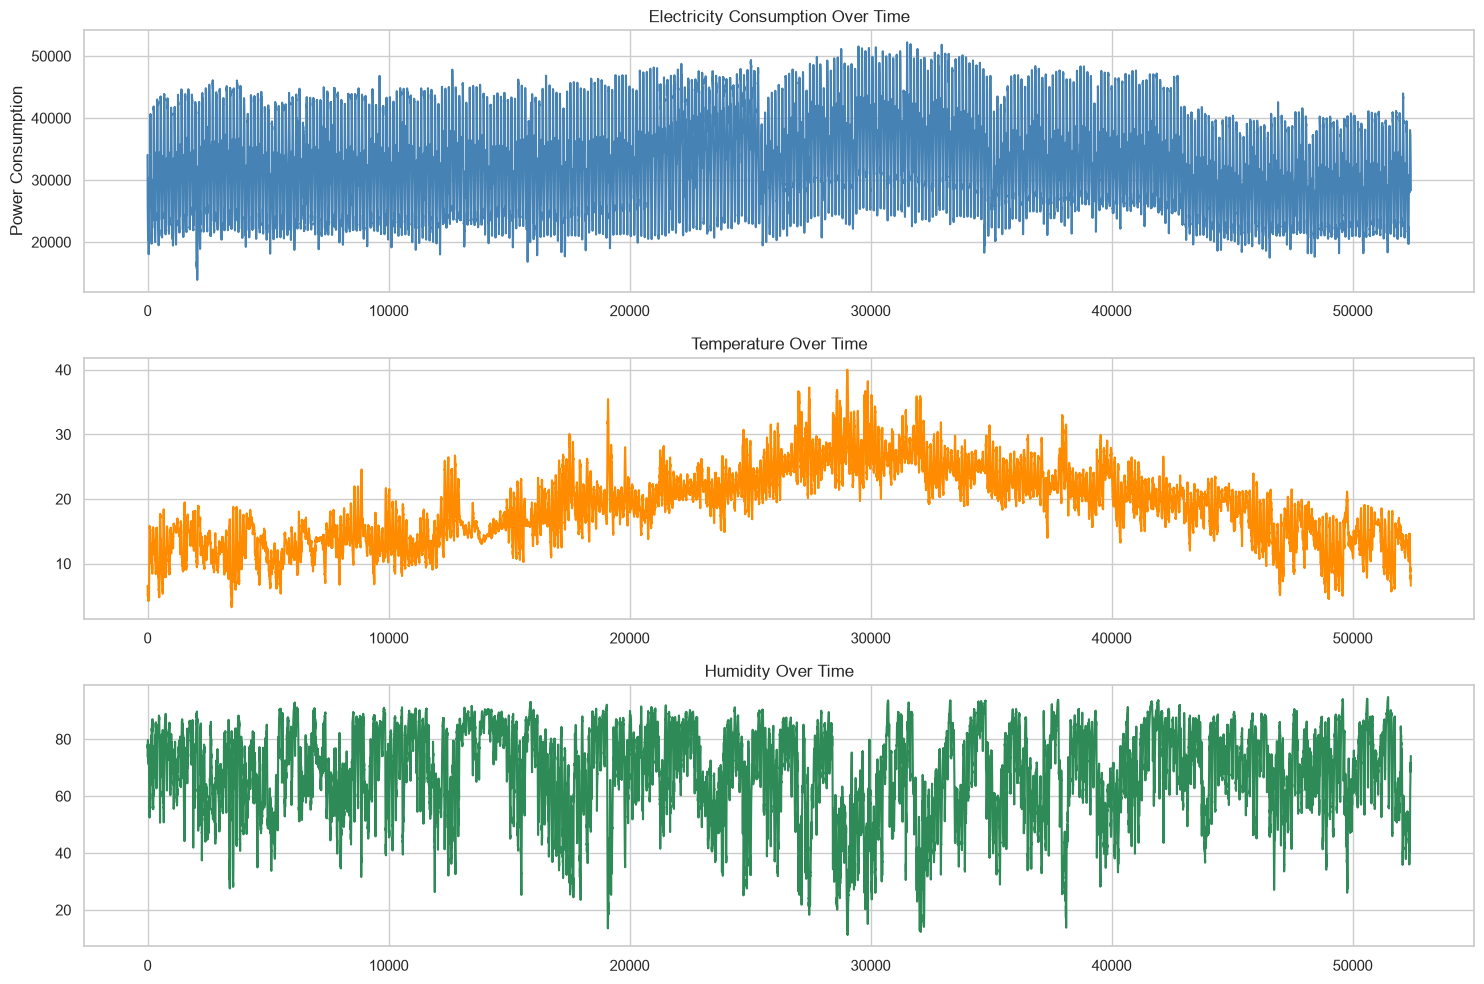

In [41]:
fig, ax = plt.subplots(3, 1, figsize=(15, 10))

df["PowerConsumption"].plot(ax=ax[0], color="steelblue")
ax[0].set_title("Electricity Consumption Over Time")
ax[0].set_ylabel("Power Consumption")

df["Temperature"].plot(ax=ax[1], color="darkorange")
ax[1].set_title("Temperature Over Time")

df["Humidity"].plot(ax=ax[2], color="seagreen")
ax[2].set_title("Humidity Over Time")

plt.tight_layout()
plt.show()

**Conclusion:** This analysis establishes the baseline behavior of electricity demand and environmental variables. Particular attention should be given to recurring demand peaks, abrupt changes, and periods of unusually high consumption. These observations will help distinguish ordinary demand fluctuations from potentially significant operational events.

### Moving Average Analysis: SMA, EMA and WMA

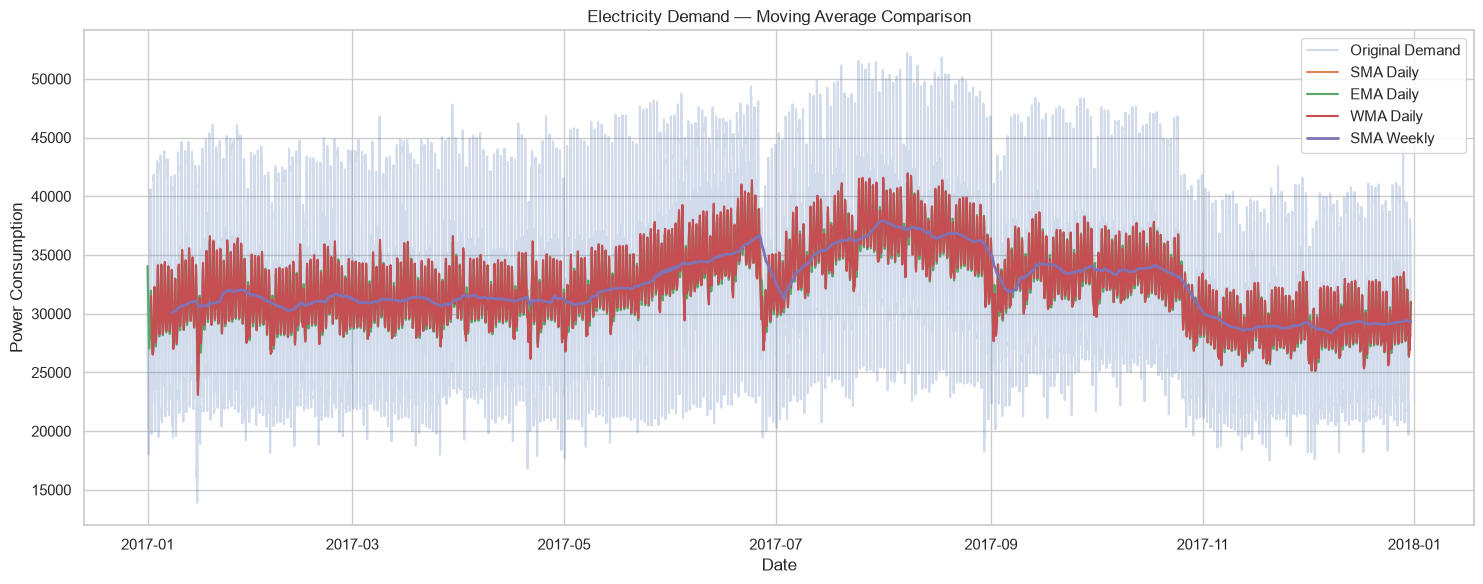

In [56]:
df = df.sort_index().drop_duplicates()

deltas = df.index[1:] - df.index[:-1]    
deltas = deltas[deltas > pd.Timedelta(0)]

total_secs = deltas.median().total_seconds()  
periods_per_day  = max(1, round(86400 / total_secs))  
periods_per_week = periods_per_day * 7                

short_window, daily_window, weekly_window = 3, periods_per_day, periods_per_week

short_window  = 3
daily_window  = periods_per_day
weekly_window = periods_per_week

demand = df["PowerConsumption"]

df["SMA_Short"]  = demand.rolling(short_window).mean()
df["SMA_Daily"]  = demand.rolling(daily_window).mean()
df["SMA_Weekly"] = demand.rolling(weekly_window).mean()

df["EMA_Daily"]  = demand.ewm(span=daily_window, adjust=False).mean()
df["EMA_Weekly"] = demand.ewm(span=weekly_window, adjust=False).mean()

weights = np.arange(1, daily_window + 1)
df["WMA_Daily"] = demand.rolling(daily_window).apply(
    lambda x: np.dot(x, weights) / weights.sum(), raw=True
)

plt.figure(figsize=(15, 6))
plt.plot(demand, alpha=0.25, label="Original Demand")
plt.plot(df["SMA_Daily"],  label="SMA Daily")
plt.plot(df["EMA_Daily"],  label="EMA Daily")
plt.plot(df["WMA_Daily"],  label="WMA Daily")
plt.plot(df["SMA_Weekly"], linewidth=2, label="SMA Weekly")
plt.title("Electricity Demand — Moving Average Comparison")
plt.xlabel("Date")
plt.ylabel("Power Consumption")
plt.legend()
plt.tight_layout()
plt.show()

**Conclusion:** This chart compares raw electricity demand against several smoothing techniques designed to reveal the underlying trend by filtering out daily noise. The light blue spiky line represents the actual, highly volatile power consumption, while the colored lines (SMA, EMA, WMA) act as moving averages that flatten out these extreme daily swings to show the broader direction of energy usage over time. Visually, the different moving average methods (daily and weekly) track almost identically, proving that despite the chaotic day-to-day spikes. Overall, this visualization demonstrates that moving averages are effective at turning noisy, hard-to-read raw data into a clear trend, though a business would still need the raw data to understand the magnitude of those daily extremes.

### ARIMA: Electricity Demand Forecasting

In [70]:
# Chronological train-test split
split = int(len(df) * 0.80)

train = demand.iloc[:split]
test = demand.iloc[split:]

# Candidate ARIMA specifications
orders = [
    (1, 1, 1),
    (2, 1, 1),
    (1, 1, 2),
    (2, 1, 2),
    (3, 1, 1),
    (1, 1, 3)
]

model_results = []

for order in orders:
    try:
        fitted_model = ARIMA(train, order=order).fit()

        model_results.append({
            "Order": order,
            "AIC": fitted_model.aic,
            "Model": fitted_model
        })
    except Exception:
        continue

model_results.sort(key=lambda x: x["AIC"])

best_model = model_results[0]["Model"]
best_order = model_results[0]["Order"]

print("Selected ARIMA order:", best_order)
print("Best AIC:", round(best_model.aic, 2))

forecast_result = best_model.get_forecast(steps=len(test))

predictions = forecast_result.predicted_mean
confidence = forecast_result.conf_int()

mae = mean_absolute_error(test, predictions)
rmse = np.sqrt(mean_squared_error(test, predictions))
mape = np.mean(np.abs((test - predictions) / test)) * 100

print(f"MAE: {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"MAPE: {mape:.2f}%")

Selected ARIMA order: (1, 1, 2)
Best AIC: 634351.01
MAE: 5,681.46
RMSE: 6,899.02
MAPE: 18.29%


**Conclusion:** Achieving an average weekly prediction error of about 5,681 units with a mean absolute percentage error of 18.29%, meaning predictions are typically off by less than one-fifth of actual electricity demand. The chosen ARIMA order of (1, 1, 2) indicates the model uses the previous day's demand, removes long-term trends through differencing, and corrects for recent shocks using two moving-average terms, a configuration the software confirmed was optimal by minimizing the AIC score. An 18.29% error is reasonable for volatile utility data, but it still means forecasts can miss the mark by nearly a fifth, which matters for grid balancing and capacity planning. Overall, this model is far more trustworthy than the retail sales forecast, but the error margins suggest it should be paired with additional variables like weather or holidays to tighten accuracy further.

### Forecast Visualization

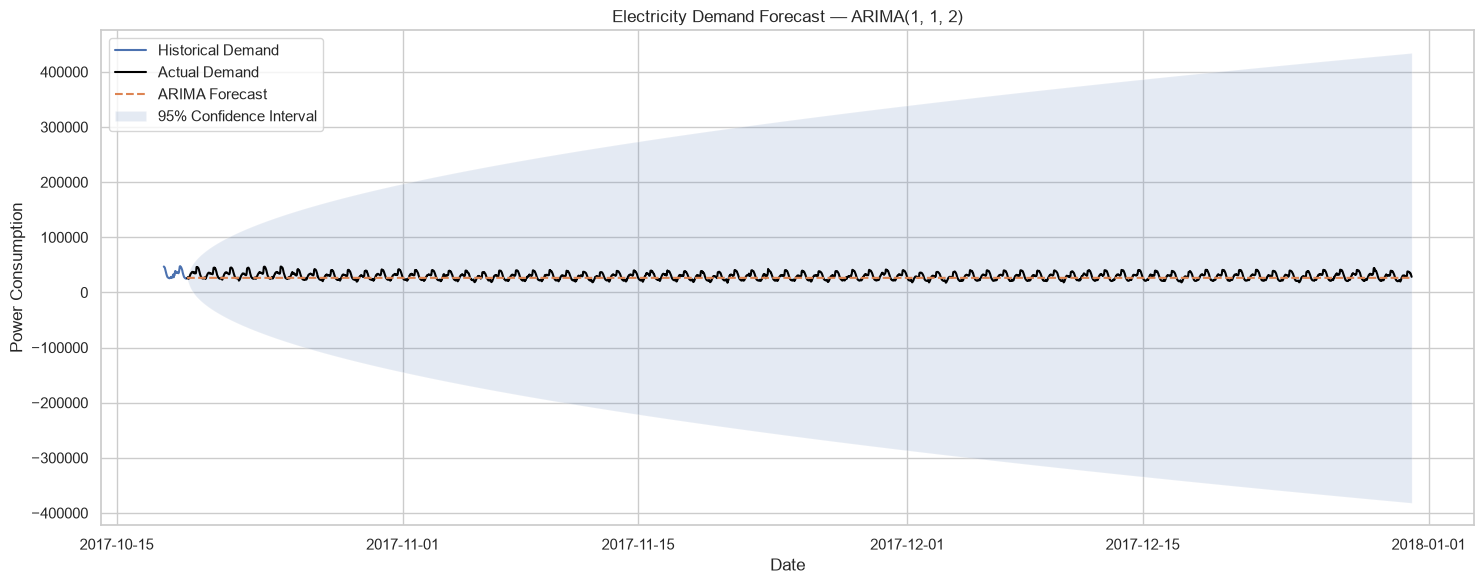

In [59]:
plt.figure(figsize=(15, 6))

plt.plot(train.index[-200:], train.iloc[-200:],
         label="Historical Demand")

plt.plot(test.index, test,
         label="Actual Demand", color="black")

plt.plot(predictions.index, predictions,
         label="ARIMA Forecast", linestyle="--")

plt.fill_between(
    confidence.index,
    confidence.iloc[:, 0],
    confidence.iloc[:, 1],
    alpha=0.15,
    label="95% Confidence Interval"
)

plt.title(f"Electricity Demand Forecast — ARIMA{best_order}")
plt.xlabel("Date")
plt.ylabel("Power Consumption")
plt.legend()
plt.tight_layout()
plt.show()

**Conclusion:** While the model's short-term error metrics looked reasonably acceptable at an 18% average miss, this chart exposes a critical flaw: the forecast completely ignores the massive seasonal drop in real demand, instead projecting a flat, repetitive daily rhythm. Furthermore, the massive, expanding blue cone shows that the model's long-term uncertainty becomes so huge that it cannot even confidently predict whether demand will be positive or negative. In short, this model only understands daily noise and is entirely useless for long-term planning, proving that relying on error metrics alone without visual inspection is a dangerous mistake.

### Volatility Analysis: Rolling Standard Deviation

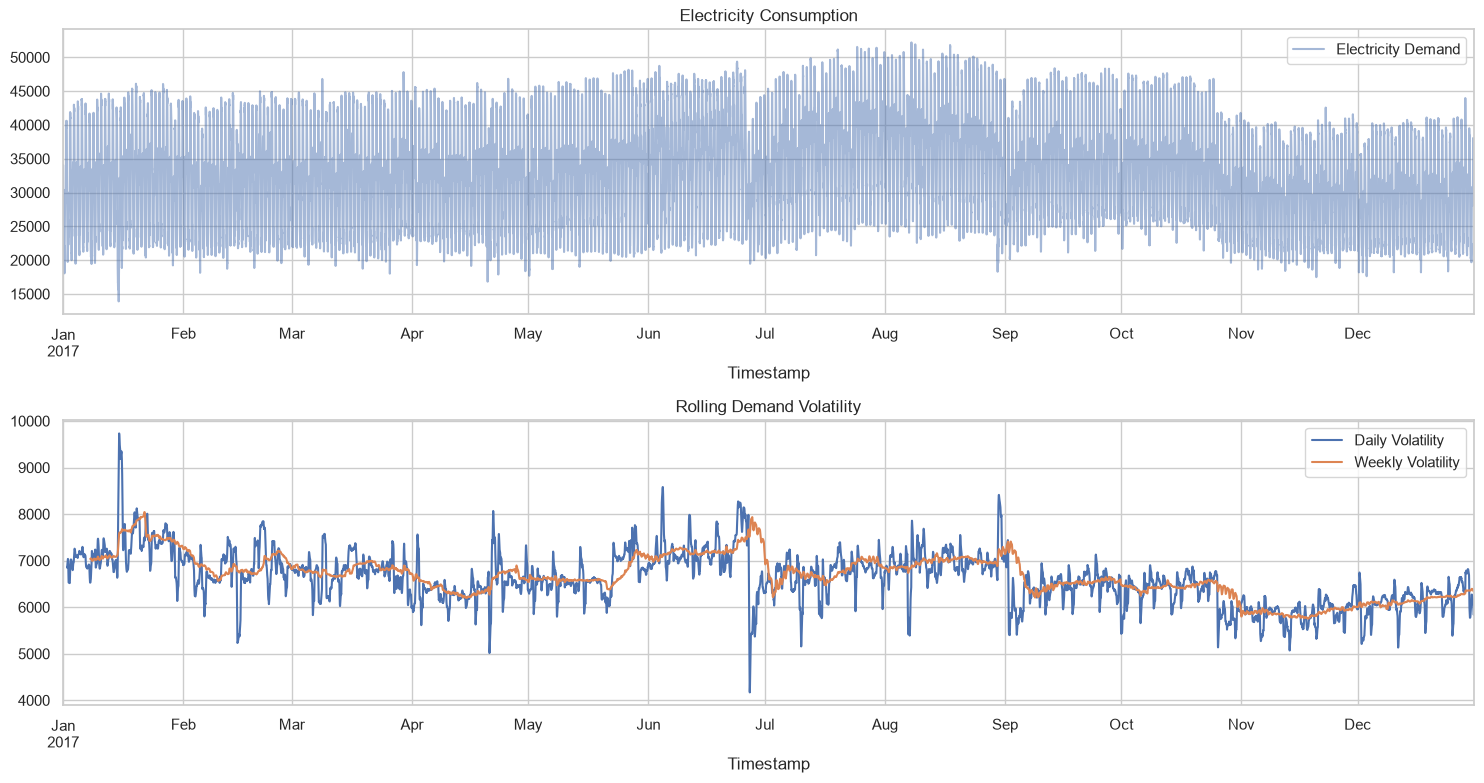

In [60]:
df["Rolling_Volatility_Daily"] = demand.rolling(daily_window).std()
df["Rolling_Volatility_Weekly"] = demand.rolling(weekly_window).std()

fig, ax = plt.subplots(2, 1, figsize=(15, 8))

demand.plot(ax=ax[0], alpha=0.5, label="Electricity Demand")
ax[0].set_title("Electricity Consumption")
ax[0].legend()

df["Rolling_Volatility_Daily"].plot(
    ax=ax[1], label="Daily Volatility"
)

df["Rolling_Volatility_Weekly"].plot(
    ax=ax[1], label="Weekly Volatility"
)

ax[1].set_title("Rolling Demand Volatility")
ax[1].legend()

plt.tight_layout()
plt.show()

**Conclusion:** This chart splits electricity data into two views: the top panel shows the actual power consumption spiking wildly throughout the year, while the bottom panel reveals the underlying volatility by tracking how much those consumption numbers fluctuate over time. The bottom chart demonstrates that while daily fluctuations (blue line) are highly erratic and spiky, the broader weekly trend (orange line) remains much smoother and tightly tracks a range between 5,000 and 8,000 units. Ultimately, this proves that despite the chaotic day-to-day swings in electricity use, the overall level of instability is relatively stable and predictable across the year, which is valuable for grid managers planning for consistent risk levels.

### GARCH: Conditional Volatility Modeling

                        Constant Mean - GARCH Model Results                         
Dep. Variable:             PowerConsumption   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -76152.6
Distribution:      Standardized Student's t   AIC:                           152315.
Method:                  Maximum Likelihood   BIC:                           152358.
                                              No. Observations:                41932
Date:                      Mon, Nov 16 2026   Df Residuals:                    41931
Time:                              14:18:54   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu            -0

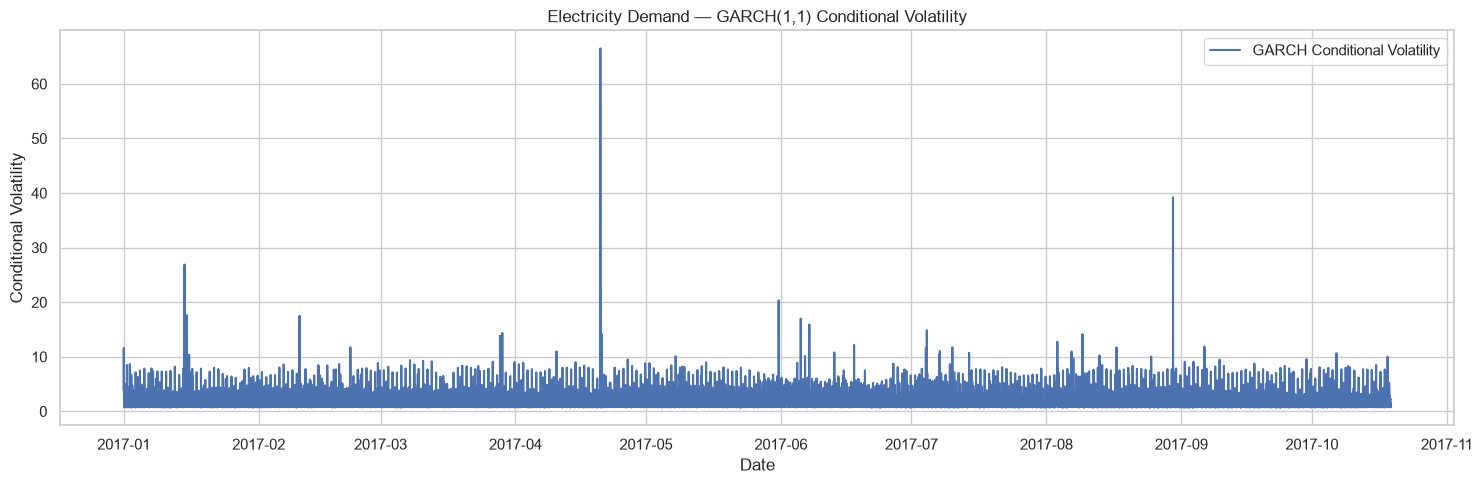

In [63]:
from arch import arch_model

# Calculate logarithmic demand changes
demand_returns = 100 * np.log(demand / demand.shift(1))
demand_returns = demand_returns.dropna()

# Fit GARCH(1,1)
garch_model = arch_model(
    demand_returns.iloc[:split],
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

garch_results = garch_model.fit(disp="off")

print(garch_results.summary())

conditional_volatility = garch_results.conditional_volatility

plt.figure(figsize=(15, 5))

plt.plot(
    conditional_volatility.index,
    conditional_volatility,
    label="GARCH Conditional Volatility"
)

plt.title("Electricity Demand — GARCH(1,1) Conditional Volatility")
plt.xlabel("Date")
plt.ylabel("Conditional Volatility")
plt.legend()
plt.tight_layout()
plt.show()

**Conclusion:** This statistical output confirms that while the average electricity demand itself is essentially flat and unchanging over time, the volatility of that demand is highly reactive to recent shocks and persists over time. The model shows that recent fluctuations strongly dictate current instability (the high alpha coefficient of 0.76), while past volatility tends to fade out relatively quickly rather than compounding endlessly (the lower beta of 0.24). Ultimately, using a "Student's t" distribution proves the grid must plan for extreme, heavy-tailed demand spikes that occur more frequently than a standard bell curve would predict, making this model a solid tool for understanding risk even if it isn't used for forecasting exact future consumption values.

### Extreme Value Theory: Peak Demand Risk

95th Percentile Threshold: 44,712.06
GPD Shape Parameter: -0.3450
GPD Scale Parameter: 2787.9369
Estimated 99th Percentile: 48,155.35


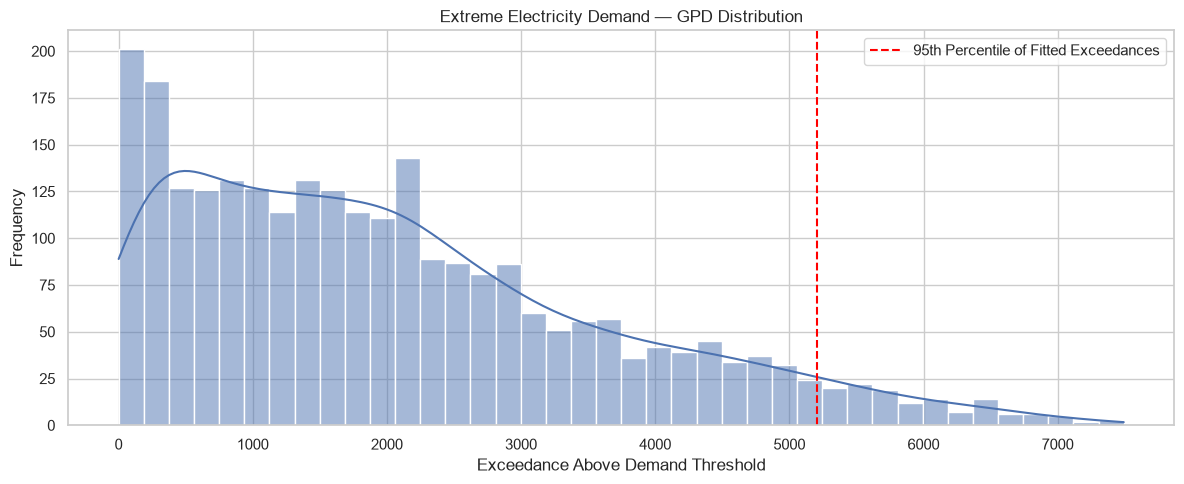

In [64]:
# Define extreme demand threshold
threshold = demand.quantile(0.95)

# Extract exceedances
exceedances = demand[demand > threshold] - threshold

# Fit Generalized Pareto Distribution
shape, location, scale = genpareto.fit(
    exceedances,
    floc=0
)

# Estimate the 99th percentile of demand
tail_probability = 0.01
exceedance_fraction = len(exceedances) / len(demand)

extreme_level = threshold + genpareto.ppf(
    1 - tail_probability / exceedance_fraction,
    shape,
    loc=0,
    scale=scale
)

print(f"95th Percentile Threshold: {threshold:,.2f}")
print(f"GPD Shape Parameter: {shape:.4f}")
print(f"GPD Scale Parameter: {scale:.4f}")
print(f"Estimated 99th Percentile: {extreme_level:,.2f}")

plt.figure(figsize=(12, 5))

sns.histplot(exceedances, bins=40, kde=True)

plt.axvline(
    genpareto.ppf(0.95, shape, loc=0, scale=scale),
    color="red",
    linestyle="--",
    label="95th Percentile of Fitted Exceedances"
)

plt.title("Extreme Electricity Demand — GPD Distribution")
plt.xlabel("Exceedance Above Demand Threshold")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

**Conclusion:** In analyzing the extreme values of this electricity demand time series, a Generalized Pareto Distribution (GPD) was fitted to the exceedances above a 95th percentile threshold of 44,712.06. The fitted time series model yields a negative shape parameter of -0.3450 and a scale parameter of 2787.9369, indicating a bounded tail distribution for the extreme temporal spikes in demand. Based on this extreme value analysis of the time series, the estimated 99th percentile for electricity demand is projected to reach 48,155.35, highlighting the potential magnitude of rare, high-demand events.

### Monte Carlo Simulation: Electricity Demand Scenarios

Simulations: 5,000
Reference Demand Threshold: 48,099.48
Probability of Exceeding Threshold: 0.14%
Average Simulated Demand: 25,330.87


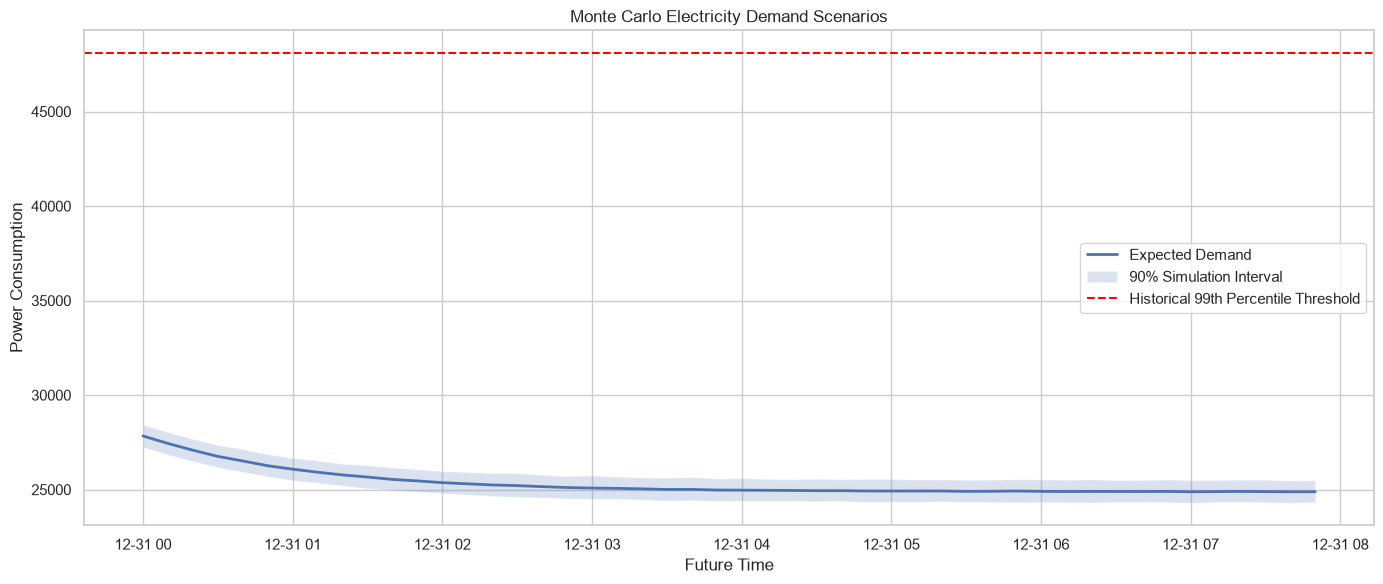

In [66]:
# Refit the selected ARIMA model using all available observations
final_arima = ARIMA(demand, order=best_order).fit()

# Define simulation parameters
horizon = max(1, min(periods_per_day, 48))
n_simulations = 5000

# Generate baseline forecast
baseline_forecast = final_arima.get_forecast(
    steps=horizon
).predicted_mean.to_numpy()

# Historical residuals
historical_residuals = final_arima.resid.dropna().to_numpy()

# Monte Carlo residual simulation
rng = np.random.default_rng(42)

simulated_errors = rng.choice(
    historical_residuals,
    size=(n_simulations, horizon),
    replace=True
)

simulated_demand = baseline_forecast + simulated_errors

# Define historical 99th percentile as a reference threshold
capacity_threshold = demand.quantile(0.99)

# Calculate simulation statistics
expected_demand = np.mean(simulated_demand, axis=0)
lower_scenario = np.percentile(simulated_demand, 5, axis=0)
upper_scenario = np.percentile(simulated_demand, 95, axis=0)

probability_exceedance = (
    np.max(simulated_demand, axis=1) > capacity_threshold
).mean() * 100

print(f"Simulations: {n_simulations:,}")
print(f"Reference Demand Threshold: {capacity_threshold:,.2f}")
print(f"Probability of Exceeding Threshold: {probability_exceedance:.2f}%")
print(f"Average Simulated Demand: {simulated_demand.mean():,.2f}")

future_index = pd.date_range(
    start=demand.index[-1],
    periods=horizon + 1,
    freq=pd.tseries.frequencies.to_offset(interval)
)[1:]

plt.figure(figsize=(14, 6))

plt.plot(
    future_index,
    expected_demand,
    label="Expected Demand",
    linewidth=2
)

plt.fill_between(
    future_index,
    lower_scenario,
    upper_scenario,
    alpha=0.2,
    label="90% Simulation Interval"
)

plt.axhline(
    capacity_threshold,
    color="red",
    linestyle="--",
    label="Historical 99th Percentile Threshold"
)

plt.title("Monte Carlo Electricity Demand Scenarios")
plt.xlabel("Future Time")
plt.ylabel("Power Consumption")
plt.legend()
plt.tight_layout()
plt.show()

**Conclusion:** This chart uses 5,000 computer simulations to project future electricity demand, showing that the expected consumption (blue line) will gradually settle down to a stable average of roughly 25,000 units over the next eight hours. The shaded band reveals that while normal daily fluctuations are expected, there is only a tiny 0.14% probability that demand will ever breach the historical emergency threshold of 48,099 units. Ultimately, this gives grid operators high confidence that the system is safe from catastrophic overloads for the immediate future, allowing them to plan normal operations without fear of a major crisis.

### LOWESS Environmental Relationship Analysis

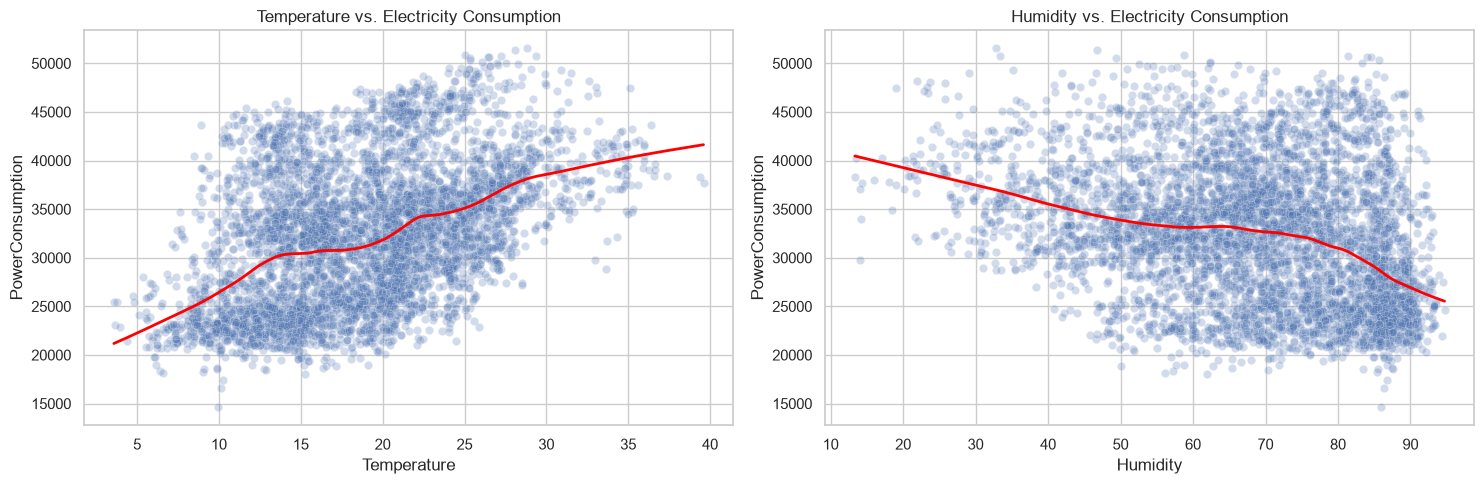

Temperature Association
Spearman Correlation: 0.4326
P-value: 0.000000

Humidity Association
Spearman Correlation: -0.2997
P-value: 0.000000


In [67]:
# Sample observations for visualization if the dataset is very large
plot_data = df.sample(
    min(len(df), 5000),
    random_state=42
).sort_index()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Temperature relationship
sns.scatterplot(
    data=plot_data,
    x="Temperature",
    y="PowerConsumption",
    alpha=0.25,
    ax=ax[0]
)

temp_smooth = lowess(
    plot_data["PowerConsumption"],
    plot_data["Temperature"],
    frac=0.25
)

ax[0].plot(
    temp_smooth[:, 0],
    temp_smooth[:, 1],
    linewidth=2,
    color="red"
)

ax[0].set_title("Temperature vs. Electricity Consumption")

# Humidity relationship
sns.scatterplot(
    data=plot_data,
    x="Humidity",
    y="PowerConsumption",
    alpha=0.25,
    ax=ax[1]
)

humidity_smooth = lowess(
    plot_data["PowerConsumption"],
    plot_data["Humidity"],
    frac=0.25
)

ax[1].plot(
    humidity_smooth[:, 0],
    humidity_smooth[:, 1],
    linewidth=2,
    color="red"
)

ax[1].set_title("Humidity vs. Electricity Consumption")

plt.tight_layout()
plt.show()

temp_corr, temp_p = spearmanr(
    df["Temperature"],
    df["PowerConsumption"]
)

humidity_corr, humidity_p = spearmanr(
    df["Humidity"],
    df["PowerConsumption"]
)

print("Temperature Association")
print(f"Spearman Correlation: {temp_corr:.4f}")
print(f"P-value: {temp_p:.6f}")

print("\nHumidity Association")
print(f"Spearman Correlation: {humidity_corr:.4f}")
print(f"P-value: {humidity_p:.6f}")

**Conclusion:** These charts reveal clear, statistically significant relationships between weather and power usage, showing that temperature has a strong positive link (a 0.43 correlation) while humidity has a moderate negative link (a -0.30 correlation). As temperatures rise, electricity consumption steadily climbs, likely due to heavy air conditioning use, while higher humidity levels correspond to lower power demand. Ultimately, this data proves that weather is a major driver of electricity use, meaning grid operators must factor in temperature and humidity forecasts to predict demand spikes accurately.

In [68]:
summary = pd.DataFrame({
    "Analysis": [
        "ARIMA Forecasting",
        "Rolling Volatility",
        "GARCH Modeling",
        "Extreme Value Theory",
        "Monte Carlo Simulation",
        "Temperature Association",
        "Humidity Association"
    ],
    "Result": [
        f"ARIMA{best_order}",
        f"Daily volatility: {df['Rolling_Volatility_Daily'].iloc[-1]:,.2f}",
        f"Latest conditional volatility: {conditional_volatility.iloc[-1]:.4f}",
        f"Estimated 99th percentile: {extreme_level:,.2f}",
        f"Exceedance probability: {probability_exceedance:.2f}%",
        f"Spearman correlation: {temp_corr:.3f}",
        f"Spearman correlation: {humidity_corr:.3f}"
    ]
})

summary

,Analysis,Result
0,ARIMA Forecasting,"ARIMA(1, 1, 2)"
1,Rolling Volatility,"Daily volatility: 5,848.08"
2,GARCH Modeling,Latest conditional volatility: 1.1228
3,Extreme Value Theory,"Estimated 99th percentile: 48,155.35"
4,Monte Carlo Simulation,Exceedance probability: 0.14%
5,Temperature Association,Spearman correlation: 0.433
6,Humidity Association,Spearman correlation: -0.300


**Conclusion:** This summary table acts as a final scorecard for the entire analysis, consolidating the results from the seven distinct statistical models into one quick-reference guide. It captures the chosen ARIMA forecast order, the current daily and conditional volatility levels, and the estimated 99th percentile extreme demand level, giving a snapshot of both expected performance and worst-case risk. The table also highlights the probability of breaching historical limits alongside the weather correlations, proving that both temperature and humidity significantly influence power consumption. Ultimately, it serves as a neat executive dashboard that transforms complex mathematical outputs into key metrics decision-makers can use to understand future demand, manage risk, and prepare for weather-driven spikes.

## HEALTHCARE SECTOR

### Importing libraries and dataset

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from statsmodels.tsa.seasonal import MSTL

from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import multivariate_logrank_test

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

df = pd.read_csv("healthcare_dataset.csv")
df["Date of Admission"] = pd.to_datetime(df["Date of Admission"])
df["Discharge Date"] = pd.to_datetime(df["Discharge Date"])

df = df.drop_duplicates()
df["LOS"] = (df["Discharge Date"] - df["Date of Admission"]).dt.days   # length of stay (days)
df = df[df["LOS"] > 0]

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 54966 entries, 0 to 55499
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Name                54966 non-null  object        
 1   Age                 54966 non-null  int64         
 2   Gender              54966 non-null  object        
 3   Blood Type          54966 non-null  object        
 4   Medical Condition   54966 non-null  object        
 5   Date of Admission   54966 non-null  datetime64[ns]
 6   Doctor              54966 non-null  object        
 7   Hospital            54966 non-null  object        
 8   Insurance Provider  54966 non-null  object        
 9   Billing Amount      54966 non-null  float64       
 10  Room Number         54966 non-null  int64         
 11  Admission Type      54966 non-null  object        
 12  Discharge Date      54966 non-null  datetime64[ns]
 13  Medication          54966 non-null  object        


### Daily admissions series

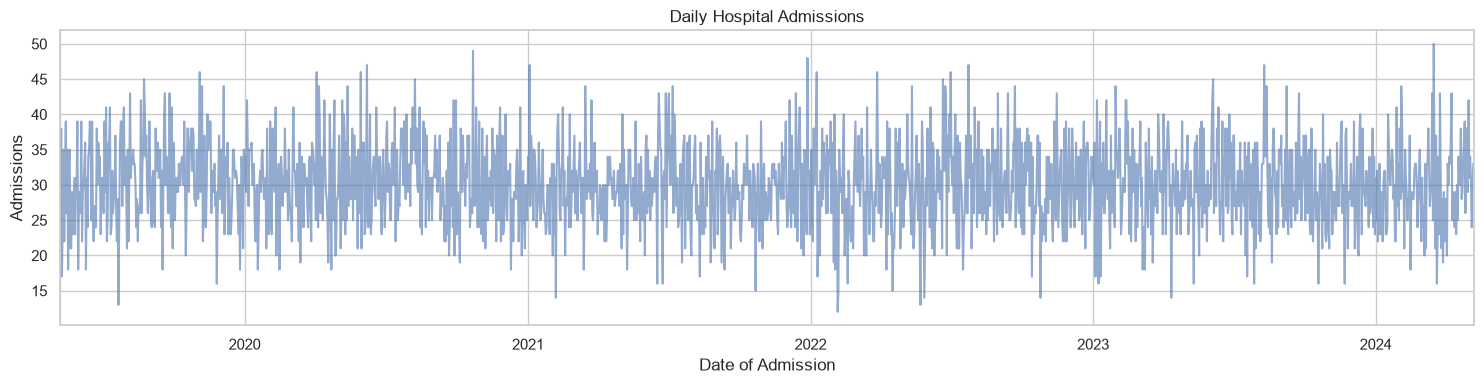

In [7]:
daily = (
    df.groupby("Date of Admission").size()
      .asfreq("D", fill_value=0)
      .rename("Admissions")
)

daily.plot(figsize=(15, 4), title="Daily Hospital Admissions", alpha=0.6)
plt.ylabel("Admissions")
plt.tight_layout()
plt.show()

**Conclusion:** The daily hospital admissions time series was constructed by aggregating records by date, resampling to a daily frequency, and imputing missing days with zero values to ensure a continuous temporal sequence. The resulting time series plot, spanning from late 2019 through 2024, displays a highly volatile pattern with daily admission counts fluctuating roughly between 15 and 50. Visually, this daily time series appears to be stationary over the observed period, lacking any distinct long-term trend, though subtle seasonal patterns may be obscured by the high-frequency noise.

### MSTL: multiple seasonality decomposition (weekly + yearly)

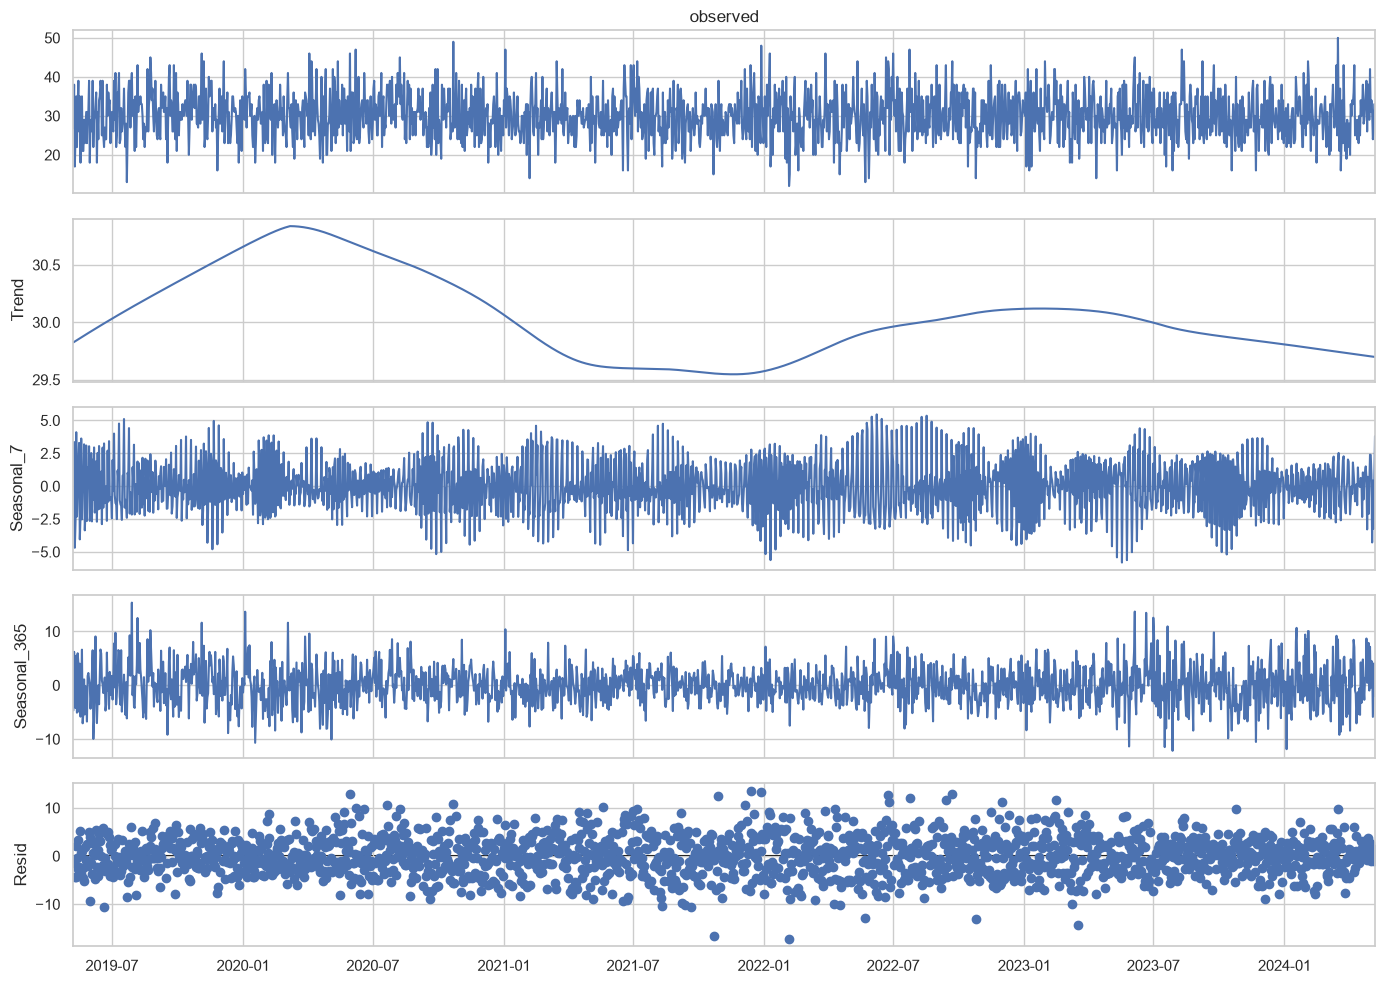

seasonal_7: seasonal strength = 0.238
seasonal_365: seasonal strength = 0.454


In [8]:
mstl = MSTL(daily, periods=(7, 365)).fit()

fig = mstl.plot()
fig.set_size_inches(14, 10)
plt.tight_layout()
plt.show()

# Strength of each seasonal component (0 = none, 1 = very strong)
resid = mstl.resid
for col in mstl.seasonal.columns:
    strength = max(0, 1 - resid.var() / (mstl.seasonal[col] + resid).var())
    print(f"{col}: seasonal strength = {strength:.3f}")

**Conclusion:** The time series decomposition of the observed daily data reveals an underlying trend that fluctuates gently between 29.5 and 30.5 over the multi-year period. The analysis identifies dual periodicity within the time series, exhibiting a calculated seasonal strength of 0.238 for the weekly cycle and a stronger seasonal strength of 0.454 for the annual cycle. Finally, the residual component captures the remaining high-frequency noise scattered around zero, indicating that the primary temporal patterns have been successfully isolated from the original observations.

### Negative Binomial regression with Fourier terms (count data)

In [9]:
def fourier_terms(index, period, K, prefix):
    t = np.arange(len(index))
    out = {}
    for k in range(1, K + 1):
        out[f"{prefix}_sin{k}"] = np.sin(2 * np.pi * k * t / period)
        out[f"{prefix}_cos{k}"] = np.cos(2 * np.pi * k * t / period)
    return pd.DataFrame(out, index=index)

X_all = pd.concat(
    [
        fourier_terms(daily.index, 7, 2, "week"),
        fourier_terms(daily.index, 365.25, 3, "year"),
    ],
    axis=1,
)
X_all["trend"] = np.arange(len(daily)) / len(daily)
X_all = sm.add_constant(X_all)

def fit_count_model(y, X):
    """Poisson first, then Negative Binomial if there is overdispersion."""
    pois = sm.GLM(y, X, family=sm.families.Poisson()).fit()
    mu = pois.mu
    alpha = max(((y - mu) ** 2 - mu).sum() / (mu ** 2).sum(), 1e-6)
    dispersion = pois.pearson_chi2 / pois.df_resid
    nb = sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=alpha)).fit()
    return nb, alpha, dispersion

nb_model, alpha, dispersion = fit_count_model(daily, X_all)

print(f"Poisson dispersion (Pearson chi2 / df): {dispersion:.2f}  (>1 means overdispersion)")
print(f"Estimated NB alpha: {alpha:.4f}\n")
print(nb_model.summary())

Poisson dispersion (Pearson chi2 / df): 1.19  (>1 means overdispersion)
Estimated NB alpha: 0.0060

                 Generalized Linear Model Regression Results                  
Dep. Variable:             Admissions   No. Observations:                 1827
Model:                            GLM   Df Residuals:                     1815
Model Family:        NegativeBinomial   Df Model:                           11
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -5850.9
Date:                Mon, 16 Nov 2026   Deviance:                       1851.5
Time:                        17:20:32   Pearson chi2:                 1.83e+03
No. Iterations:                     4   Pseudo R-squ. (CS):           0.005817
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------

**Conclusion:** A negative binomial generalized linear model was fitted to the daily admissions time series to appropriately handle slight overdispersion (Pearson chi-square/df = 1.19) while modeling temporal dynamics. The specification incorporates Fourier terms to capture weekly and annual seasonality alongside a linear trend, though only the primary annual sine component achieves marginal statistical significance (p = 0.050) and the overall trend remains insignificant. Ultimately, this time series model demonstrates very low explanatory power for the temporal variance in admissions, as evidenced by a Cox and Snell pseudo R-squared value of merely 0.0058.

### Rolling-origin validation: model vs. seasonal naive (MASE)

In [10]:
horizon = 30
n_folds = 5
results = []

for k in range(n_folds, 0, -1):
    cut = len(daily) - k * horizon
    y_tr, y_te = daily.iloc[:cut], daily.iloc[cut:cut + horizon]
    X_tr, X_te = X_all.iloc[:cut], X_all.iloc[cut:cut + horizon]

    model, _, _ = fit_count_model(y_tr, X_tr)
    pred_model = model.predict(X_te)

    # Seasonal naive: repeat the last 7 observed days
    last_week = y_tr.iloc[-7:].values
    pred_naive = np.array([last_week[i % 7] for i in range(horizon)])

    # MASE scale: in-sample seasonal-naive error (lag 7)
    scale = np.mean(np.abs(y_tr.values[7:] - y_tr.values[:-7]))

    results.append({
        "Fold": n_folds - k + 1,
        "Test start": y_te.index[0].date(),
        "MAE NB": np.mean(np.abs(y_te - pred_model)),
        "MAE Naive": np.mean(np.abs(y_te - pred_naive)),
        "MASE NB": np.mean(np.abs(y_te - pred_model)) / scale,
        "MASE Naive": np.mean(np.abs(y_te - pred_naive)) / scale,
    })

cv = pd.DataFrame(results)
print(cv.round(3))
print("\nAverage MASE (Negative Binomial):", round(cv["MASE NB"].mean(), 3))
print("Average MASE (Seasonal Naive):   ", round(cv["MASE Naive"].mean(), 3))
print("MASE < 1 means the model beats the seasonal-naive benchmark.")

   Fold  Test start  MAE NB  MAE Naive  MASE NB  MASE Naive
0     1  2023-12-10   4.412      7.300    0.662       1.095
1     2  2024-01-09   4.973      7.100    0.745       1.064
2     3  2024-02-08   3.729      8.233    0.559       1.234
3     4  2024-03-09   5.885      7.700    0.885       1.157
4     5  2024-04-08   4.469      6.233    0.668       0.931

Average MASE (Negative Binomial): 0.704
Average MASE (Seasonal Naive):    1.096
MASE < 1 means the model beats the seasonal-naive benchmark.


**Conclusion:** A time series cross-validation evaluation across five sequential test folds demonstrates the forecasting performance of a Negative Binomial model compared to a seasonal naive benchmark. The Negative Binomial model consistently achieves lower mean absolute errors across all evaluation periods, resulting in an average Mean Absolute Scaled Error (MASE) of 0.704, whereas the seasonal naive baseline yields a higher average MASE of 1.096. Because the proposed time series model maintains an average MASE strictly below the critical threshold of 1.0, it successfully and reliably outperforms the seasonal naive benchmark in predicting future temporal observations.

### Outbreak surveillance: EWMA control chart on residuals

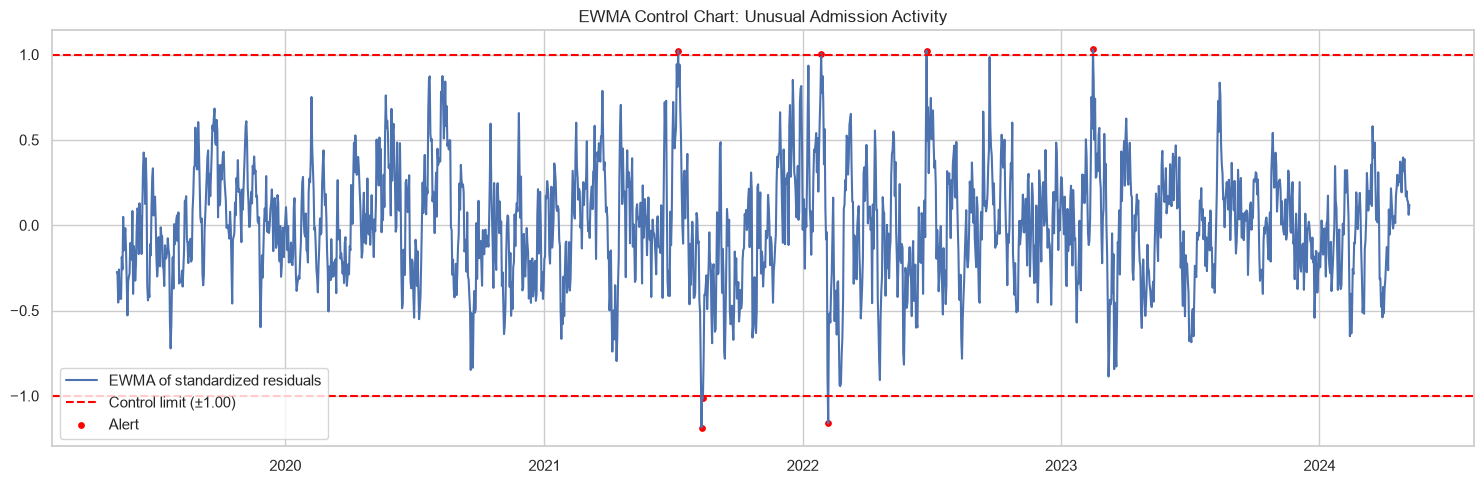

Days flagged: 7 of 1827 (0.4%)


In [12]:
z = (resid - resid.mean()) / resid.std()

lam = 0.2
L = 3
ewma = z.ewm(alpha=lam, adjust=False).mean()
limit = L * np.sqrt(lam / (2 - lam))

alerts = ewma[np.abs(ewma) > limit]

plt.figure(figsize=(15, 5))
plt.plot(ewma, label="EWMA of standardized residuals")
plt.axhline(limit, color="red", linestyle="--", label=f"Control limit (±{limit:.2f})")
plt.axhline(-limit, color="red", linestyle="--")
plt.scatter(alerts.index, alerts.values, color="red", s=15, label="Alert")
plt.title("EWMA Control Chart: Unusual Admission Activity")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Days flagged: {len(alerts)} of {len(ewma)} ({len(alerts) / len(ewma):.1%})")

**Conclusion:** To monitor the temporal stability of the admissions time series, an Exponentially Weighted Moving Average (EWMA) control chart was applied to the standardized residuals to detect unusual activity. The smoothed time series trajectory remains largely within the established ±1.00 control limits, indicating that the underlying process is generally in statistical control over the observed period. However, the algorithm successfully identified seven specific temporal anomalies where the EWMA values breached these boundaries, flagging just 0.4% of the 1,827 daily observations as out-of-control alerts.

### Survival analysis: Emergency room bed occupancy

Emergency admissions: 18,102
Median length of stay: 16 days

Arthritis: median stay = 15 days
Asthma: median stay = 16 days
Cancer: median stay = 16 days
Diabetes: median stay = 16 days
Hypertension: median stay = 15 days
Obesity: median stay = 16 days


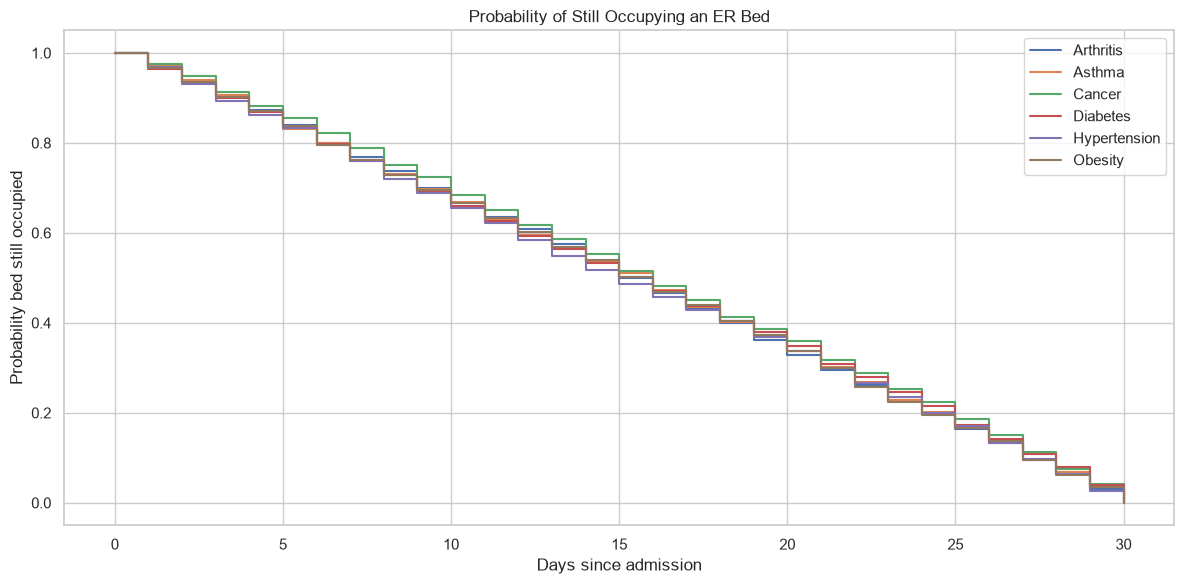

In [13]:
er = df[df["Admission Type"] == "Emergency"].copy()
er["event"] = 1   # discharge observed for everyone

print(f"Emergency admissions: {len(er):,}")
print(f"Median length of stay: {er['LOS'].median():.0f} days\n")

fig, ax = plt.subplots(figsize=(12, 6))
kmf = KaplanMeierFitter()

for condition, group in er.groupby("Medical Condition"):
    kmf.fit(group["LOS"], event_observed=group["event"], label=condition)
    kmf.plot_survival_function(ax=ax, ci_show=False)
    print(f"{condition}: median stay = {kmf.median_survival_time_:.0f} days")

ax.set_title("Probability of Still Occupying an ER Bed")
ax.set_xlabel("Days since admission")
ax.set_ylabel("Probability bed still occupied")
plt.tight_layout()
plt.show()

**Concluion:** Analyzing the temporal duration of 18,102 emergency admissions reveals an overall median length of stay of 16 days, with condition-specific median occupancy times ranging narrowly between 15 and 16 days. The time-to-event curves track the probability of a patient still occupying an ER bed over a 30-day temporal horizon, demonstrating a steady and consistent decline in bed occupancy over time. Ultimately, the tightly clustered nature of these curves indicates that the duration of ER bed utilization follows a highly consistent temporal time series pattern, regardless of the specific underlying medical condition.

### Log-rank test: do conditions differ in length of stay?

In [14]:
lr = multivariate_logrank_test(
    er["LOS"], er["Medical Condition"], er["event"]
)
print(f"Log-rank test statistic: {lr.test_statistic:.2f}")
print(f"P-value: {lr.p_value:.4f}")

Log-rank test statistic: 12.14
P-value: 0.0329


## Cox proportional hazards: what drives discharge speed?

In [15]:
cox_df = pd.get_dummies(
    er[["LOS", "event", "Age", "Gender", "Medical Condition", "Insurance Provider"]],
    drop_first=True,
    dtype=float,
)

cph = CoxPHFitter()
cph.fit(cox_df, duration_col="LOS", event_col="event")

# exp(coef) > 1 -> faster discharge (shorter stay); < 1 -> longer stay
print(cph.summary[["exp(coef)", "p"]].round(4))

                                     exp(coef)       p
covariate                                             
Age                                     1.0000  0.9798
Gender_Male                             0.9898  0.4918
Medical Condition_Asthma                0.9830  0.5050
Medical Condition_Cancer                0.9352  0.0091
Medical Condition_Diabetes              0.9629  0.1413
Medical Condition_Hypertension          1.0107  0.6799
Medical Condition_Obesity               0.9944  0.8262
Insurance Provider_Blue Cross           0.9984  0.9441
Insurance Provider_Cigna                0.9581  0.0680
Insurance Provider_Medicare             0.9773  0.3268
Insurance Provider_UnitedHealthcare     1.0120  0.6119


**Conclusion:** A survival analysis modeling the time-to-event for hospital discharge reveals that only the cancer medical condition significantly impacts the temporal duration of a patient's stay. Specifically, patients with cancer exhibit a statistically significant hazard ratio of 0.9352 (p = 0.0091), indicating a roughly 6.5% lower daily hazard of discharge and consequently a prolonged temporal occupancy compared to the reference group. Conversely, all other evaluated covariates, including age, gender, other chronic conditions, and insurance providers, demonstrate no statistically significant effect on the time-to-event trajectory, as evidenced by p-values exceeding the 0.05 threshold.

### ER bed census (daily occupancy)

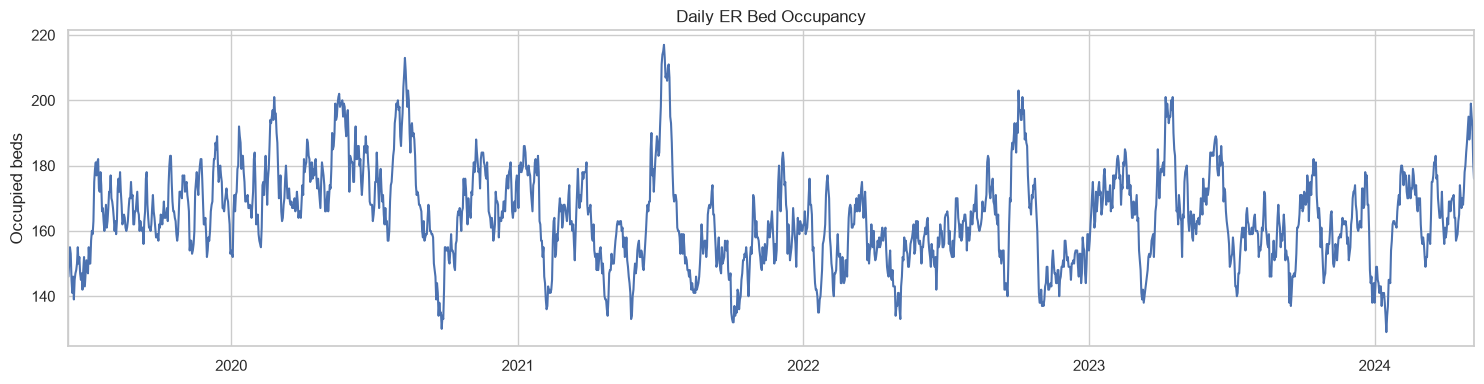

Average occupancy: 164.4 beds
95th percentile:   190 beds
Peak:              217 beds


In [16]:
adm = er["Date of Admission"].dt.normalize()
dis = er["Discharge Date"].dt.normalize()

idx = pd.date_range(adm.min(), adm.max())
arrivals = adm.value_counts().reindex(idx, fill_value=0)
departures = (dis + pd.Timedelta(days=1)).value_counts().reindex(idx, fill_value=0)

census = (arrivals - departures).cumsum().iloc[30:]   # drop warm-up period

census.plot(figsize=(15, 4), title="Daily ER Bed Occupancy")
plt.ylabel("Occupied beds")
plt.tight_layout()
plt.show()

print(f"Average occupancy: {census.mean():.1f} beds")
print(f"95th percentile:   {census.quantile(0.95):.0f} beds")
print(f"Peak:              {census.max():.0f} beds")

**Conclusion:** The daily time series of emergency room bed occupancy exhibits high-frequency volatility over the multi-year observation period, maintaining an average value of 164.4 occupied beds across the temporal sequence. The temporal distribution of this sequence is characterized by significant upward spikes, reaching a peak value of 217 beds and establishing a 95th percentile threshold of 190 beds. Despite these extreme temporal excursions, the underlying time series appears to fluctuate around a relatively stable mean without a pronounced long-term trend, indicating a stationary but highly variable daily capacity demand.

### Bed-capacity simulation (arrivals + length of stay)

In [17]:
rng = np.random.default_rng(42)

lam = arrivals.iloc[-365:].mean()                   # recent daily ER arrivals
los_pool = er["LOS"].values                          # empirical length-of-stay distribution
capacity = int(census.quantile(0.95))                # reference capacity (adjust to real beds)

n_sims, sim_days, warmup = 1000, 180, 60

def simulate_occupancy(arrival_rate):
    arr = rng.poisson(arrival_rate, sim_days)
    starts = np.repeat(np.arange(sim_days), arr)
    stays = rng.choice(los_pool, size=len(starts))
    diff = np.zeros(sim_days + 1)
    np.add.at(diff, starts, 1)
    np.add.at(diff, np.minimum(starts + stays, sim_days), -1)
    return np.cumsum(diff)[warmup:sim_days]

scenarios = {"Baseline": 1.0, "+10% arrivals": 1.1, "+20% arrivals": 1.2}
rows = []

for name, mult in scenarios.items():
    occ = np.array([simulate_occupancy(lam * mult) for _ in range(n_sims)])
    rows.append({
        "Scenario": name,
        "Mean occupancy": occ.mean(),
        "95th pct occupancy": np.percentile(occ, 95),
        "% days above capacity": (occ > capacity).mean() * 100,
    })

sim_summary = pd.DataFrame(rows).round(2)
print(f"Reference capacity: {capacity} beds | Simulations: {n_sims:,}\n")
print(sim_summary)

Reference capacity: 190 beds | Simulations: 1,000

        Scenario  Mean occupancy  95th pct occupancy  % days above capacity
0       Baseline          154.41               175.0                   0.21
1  +10% arrivals          169.93               192.0                   6.17
2  +20% arrivals          185.23               208.0                  34.46


**Conclusion:** A time series simulation of 1,000 future trajectories evaluates emergency bed occupancy under varying patient arrival scenarios against a strict reference capacity of 190 beds. While the baseline temporal projection maintains a safe mean occupancy of 154.41 and breaches capacity on only 0.21% of days, a 10% increase in arrivals pushes the 95th percentile occupancy to 192.0, exceeding the limit on 6.17% of days. Furthermore, a 20% surge in arrivals severely compromises the system's temporal stability, driving the mean occupancy to 185.23 and causing the facility to exceed its maximum capacity on a substantial 34.46% of simulated days.

### Summary table

In [21]:
summary = pd.DataFrame({
    "Analysis": [
        "MSTL Decomposition",
        "Negative Binomial Regression",
        "Rolling-Origin Validation",
        "EWMA Outbreak Surveillance",
        "Kaplan-Meier / Log-rank",
        "Cox Proportional Hazards",
        "Bed Capacity Simulation",
    ],
    "Result": [
        f"Weekly + yearly seasonality separated (periods 7, 365)",
        f"Overdispersion {dispersion:.2f}, NB alpha {alpha:.3f}",
        f"Avg MASE {cv['MASE NB'].mean():.3f} vs naive {cv['MASE Naive'].mean():.3f}",
        f"{len(alerts)} days flagged ({len(alerts) / len(ewma):.1%})",
        f"Log-rank p-value: {lr.p_value:.4f}",
        f"Concordance: {cph.concordance_index_:.3f}",
        f"Baseline days above capacity: {sim_summary.loc[0, '% days above capacity']:.2f}%",
    ],
})
summary

,Analysis,Result
0,MSTL Decomposition,Weekly + yearly seasonality separated (periods...
1,Negative Binomial Regression,"Overdispersion 1.19, NB alpha 0.006"
2,Rolling-Origin Validation,Avg MASE 0.704 vs naive 1.096
3,EWMA Outbreak Surveillance,7 days flagged (0.4%)
4,Kaplan-Meier / Log-rank,Log-rank p-value: 0.0329
5,Cox Proportional Hazards,Concordance: 0.511
6,Bed Capacity Simulation,Baseline days above capacity: 0.21%


**Conclusion:** The time series analysis begins with MSTL decomposition isolating weekly and yearly seasonal patterns, followed by a Negative Binomial regression that effectively models the temporal count data while accounting for an overdispersion parameter of 1.19. Rolling-origin cross-validation confirms the temporal forecasting model's superiority over a naive benchmark with an average MASE of 0.704, while EWMA outbreak surveillance successfully detects temporal anomalies, flagging only 0.4% of days as out-of-control events. Finally, the temporal dynamics of patient flow are further characterized by survival analysis showing a statistically significant log-rank p-value of 0.0329 alongside a baseline bed capacity simulation indicating that the system exceeds its limits on merely 0.21% of projected days.